# 04c — The simulation runs pooled

The baseline (`1a872c09`, D96) and the regression run (`e097f78e`) described
as **one sample of the agent's behaviour**: 31 cases, 352 executions. The two
runs share one configuration (`04_regress` proves it), so pooled they are two
draws of the same system, and the pooled numbers describe that system rather
than a difference between runs.

**No comparison here.** Pair-wise verdicts, pass rates and score changes
against the baseline entry are `04b`'s. This notebook reads the stored runs
only (no judge is called) and reports point-wise judge scores (D34), structural
outcomes, execution failures, recovered tool errors, latency and cost over the
pooled executions. Each pooled figure is shown with the per-run values beside
it, so a reader can see that pooling does not hide a split.

Descriptive only (D104): counts, means, standard deviations, medians and
quartiles, with no interval and no test. Standard deviations are sample SDs
(`ddof = 1`). Figures are written to `figures/pooled/` as PDF and PNG.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parents[1]))

import matplotlib.pyplot as plt
import pandas as pd

from src import analysis, db, figures, survey

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

# --- parameters -------------------------------------------------------------
RUN_IDS = {
    "baseline": "1a872c09-7070-4789-a806-904969f9185d",    # B10, adopted (D96)
    "regression": "e097f78e-3326-4aea-acaa-0b904d3b0a1c",  # B11
}
# ---------------------------------------------------------------------------

figures.setup()
save = figures.Saver("pooled")
pct = "{:.1%}".format

frames = {name: survey.run_frame(rid) for name, rid in RUN_IDS.items()}
pooled = pd.concat([f.assign(run=name) for name, f in frames.items()], ignore_index=True)
pooled["seed"] = pooled["case"].str.contains("__").map({False: "seed", True: "follow-up"})
for name, f in frames.items():
    print(f"{name} {RUN_IDS[name][:8]}: {len(f)} executions, {f.attrs.get('superseded_attempts', 0)} superseded "
          f"attempts left out (D53)")
print(f"pooled: {pooled['case'].nunique()} cases, {len(pooled)} executions")

baseline 1a872c09: 176 executions, 0 superseded attempts left out (D53)
regression e097f78e: 176 executions, 0 superseded attempts left out (D53)
pooled: 31 cases, 352 executions


## 1. Overview

One row per measure; the pooled column is the one to report, the per-run
columns show where it comes from.

In [2]:
def summary(f):
    n = len(f)
    s = f["score"].dropna()
    failed = int(f["error"].notna().sum())
    clean = int((f["structural"] == "none").sum())
    return {
        "cases": f["case"].nunique(),
        "executions": n,
        "execution failures": f"{failed}/{n} = {pct(failed / n)}",
        "structurally clean": f"{clean}/{n} = {pct(clean / n)}",
        "scored": f"{len(s)}/{n}",
        "judge score mean ± sd": f"{s.mean():.2f} ± {s.std():.2f}",
        "judge score median [IQR]": f"{s.median():.0f} [{s.quantile(.25):.0f}–{s.quantile(.75):.0f}]",
        "judge score min–max": f"{s.min():.0f}–{s.max():.0f}",
        "latency mean ± sd, s": f"{f['latency_ms'].mean() / 1000:.1f} ± {f['latency_ms'].std() / 1000:.1f}",
        "latency median / p90, s": f"{f['latency_ms'].median() / 1000:.1f} / {f['latency_ms'].quantile(.9) / 1000:.1f}",
        "tokens per execution mean ± sd": f"{f['tokens'].mean():,.0f} ± {f['tokens'].std():,.0f}",
        "cost total, USD": f"{f['cost_usd'].sum():.2f}",
        "cost per execution mean ± sd, US cents": f"{f['cost_usd'].mean() * 100:.3f} ± {f['cost_usd'].std() * 100:.3f}",
    }

pd.DataFrame({"pooled": summary(pooled), **{name: summary(f) for name, f in frames.items()}})

,pooled,baseline,regression
cases,31,31,31
executions,352,176,176
execution failures,0/352 = 0.0%,0/176 = 0.0%,0/176 = 0.0%
structurally clean,333/352 = 94.6%,165/176 = 93.8%,168/176 = 95.5%
scored,352/352,176/176,176/176
judge score mean ± sd,9.37 ± 1.13,9.26 ± 1.34,9.48 ± 0.87
judge score median [IQR],10 [9–10],10 [9–10],10 [9–10]
judge score min–max,1–10,1–10,6–10
"latency mean ± sd, s",25.4 ± 12.7,25.7 ± 12.7,25.1 ± 12.6
"latency median / p90, s",19.9 / 49.2,20.5 / 49.2,19.7 / 49.1


## 2. Point-wise judge scores

The judge's 1–10 score of every execution's first reply (D34). The overall SD
mixes two things: cases differ in how well the agent does them, and the same
case scores differently from one execution to the next. The **within-case SD**
isolates the second: the square root of the mean per-case variance, each case
pooled over both runs' executions. It is the spread a reader should expect
when the same request is repeated.

In [3]:
s = pooled.dropna(subset=["score"])
per_case_var = s.groupby("case")["score"].var(ddof=1)
within = per_case_var.mean() ** 0.5
between = s.groupby("case")["score"].mean().std()
print(f"pooled judge score: mean {s['score'].mean():.2f}, sd {s['score'].std():.2f}, n = {len(s)}")
print(f"  within-case sd (repeating the same case): {within:.2f}  over {per_case_var.notna().sum()} cases")
print(f"  sd of the case means (between cases):     {between:.2f}")
print(f"  cases whose executions all got the same score: {int((per_case_var == 0).sum())} of {len(per_case_var)}")

dist = pd.DataFrame({"pooled": s["score"].value_counts(),
                     **{name: f["score"].value_counts() for name, f in frames.items()}}
                    ).reindex(range(1, 11)).fillna(0).astype(int)
dist.T

pooled judge score: mean 9.37, sd 1.13, n = 352
  within-case sd (repeating the same case): 0.70  over 31 cases
  sd of the case means (between cases):     0.85
  cases whose executions all got the same score: 12 of 31


score,1,2,3,4,5,6,7,8,9,10
pooled,1,1,0,1,0,2,15,49,48,235
baseline,1,1,0,1,0,1,11,22,27,112
regression,0,0,0,0,0,1,4,27,21,123


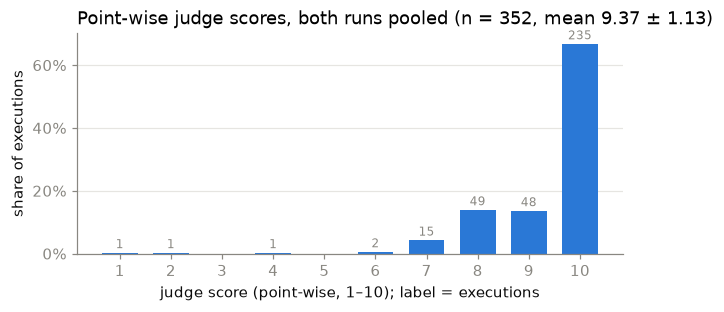

In [4]:
# Figure P1 — pooled score distribution (share of executions per score).
counts = dist["pooled"]
fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.bar(counts.index, counts / counts.sum(), width=0.7, color=figures.SERIES)
for x, c in counts.items():
    if c:
        ax.annotate(str(c), (x, c / counts.sum()), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=8, color=figures.MUTED)
ax.set_xticks(range(1, 11)); ax.set_xlabel("judge score (point-wise, 1–10); label = executions")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_ylabel("share of executions")
ax.grid(axis="y", color=figures.GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title(f"Point-wise judge scores, both runs pooled "
             f"(n = {counts.sum()}, mean {s['score'].mean():.2f} ± {s['score'].std():.2f})")
save(fig, "P1_score_distribution"); plt.show()

**By function and by provenance.** The same statistics per function of §1.4
(the case's declared function) and for seeds against their metamorphic
follow-ups.

In [5]:
def score_stats(group):
    return group["score"].agg(["count", "mean", "std", "median", "min", "max"]).round(2)

by_function = s.groupby("function").pipe(score_stats)
by_provenance = s.groupby("seed").pipe(score_stats)
display(by_function)
by_provenance

,count,mean,std,median,min,max
function,,,,,,
advisory,64,9.92,0.27,10.0,9,10
factual_qa,112,8.71,1.56,9.0,1,10
scheduling,104,9.69,0.70,10.0,6,10
venue_lookup,72,9.43,0.84,10.0,7,10


,count,mean,std,median,min,max
seed,,,,,,
follow-up,144,9.51,0.89,10.0,6,10
seed,208,9.27,1.27,10.0,1,10


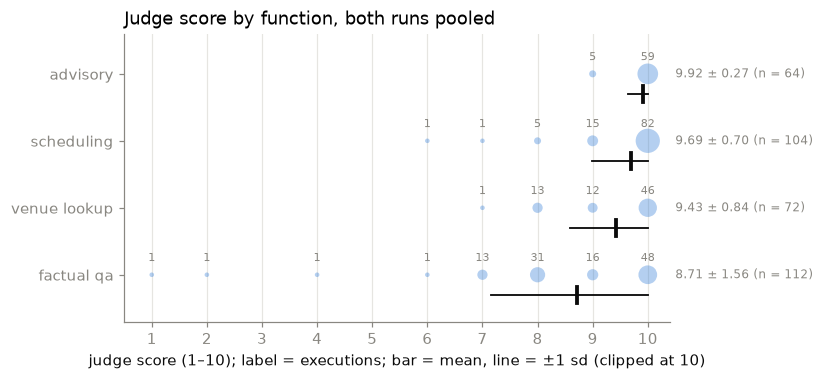

In [6]:
# Figure P2 — score per function: a circle per score, area and label = executions;
# bar = mean, line = ±1 sd.
fns = by_function.sort_values("mean").index.tolist()
fig, ax = plt.subplots(figsize=(6.4, 0.6 * len(fns) + 1))
for j, fn in enumerate(fns):
    counts = s.loc[s["function"] == fn, "score"].value_counts()
    ax.scatter(counts.index, [j] * len(counts), s=[6 + 3 * c for c in counts], color=figures.SERIES,
               alpha=0.35, linewidth=0, zorder=2)
    for x, c in counts.items():
        ax.annotate(str(c), (x, j), xytext=(0, 9), textcoords="offset points", ha="center",
                    fontsize=7, color=figures.MUTED)
    m, sd = by_function.loc[fn, "mean"], by_function.loc[fn, "std"]
    ax.plot([m - sd, min(m + sd, 10)], [j - 0.3, j - 0.3], color=figures.INK, linewidth=1.2, zorder=3)
    ax.plot([m, m], [j - 0.42, j - 0.18], color=figures.INK, linewidth=2.5, zorder=3)
    ax.annotate(f"{m:.2f} ± {sd:.2f} (n = {counts.sum()})", (10.5, j), va="center", fontsize=8,
                color=figures.MUTED, annotation_clip=False)
ax.set_yticks(range(len(fns)), [f.replace("_", " ") for f in fns])
ax.set_ylim(-0.7, len(fns) - 0.4)
ax.set_xlim(0.5, 10.4); ax.set_xticks(range(1, 11))
ax.set_xlabel("judge score (1–10); label = executions; bar = mean, line = ±1 sd (clipped at 10)")
ax.grid(axis="x", color=figures.GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title("Judge score by function, both runs pooled")
save(fig, "P2_score_by_function"); plt.show()

**Per case.** Pooled over both runs, so each seed has 16 executions and
each follow-up 8. Sorted by mean, lowest first: the top of the table is where
the agent is weakest.

In [7]:
per_case = s.groupby(["function", "case"])["score"].agg(["count", "mean", "std", "min", "max"]).round(2)
per_case.sort_values(["mean", "std"], ascending=[True, False])

count   mean   std  min  max
function     case                                                                            
factual_qa   factual_qa_lisbon_surf_conditions                      16   6.62  2.36    1    9
             factual_qa_lisbon_november_weather__dir1_july_i...      8   7.62  0.74    7    9
             factual_qa_lisbon_november_weather                     16   8.00  0.37    7    9
             factual_qa_lisbon_november_weather__inv1_paraph...      8   8.00  0.00    8    8
venue_lookup venue_lookup_sintra_lunch                              16   8.50  0.63    8   10
scheduling   scheduling_belem_morning__dir3_a_full_day               8   8.88  1.55    6   10
factual_qa   factual_qa_lisbon_forecast_next_days                   16   8.94  1.06    7   10
venue_lookup venue_lookup_sintra_lunch__dir2_lisbon_day              8   9.12  1.13    7   10
             venue_lookup_sintra_lunch__dir1_coffee_not_lunch        8   9.12  0.83    8   10
scheduling   scheduling_afternoon_then_tram                         16   9.44  0.81    8   10
             scheduling_belem_morning__dir2_on_the_9th               8   9.50  0.76    8   10
             scheduling_move_tram__dir1_put_the_monastery_on         8   9.62  0.52    9   10
factual_qa   factual_qa_lisbon_trip_forecast                        16   9.62  0.50    9   10
scheduling   scheduling_belem_morning                               16   9.69  0.60    8   10
advisory     advisory_packing_list__inv1_paraphrase                  8   9.75  0.46    9   10
             advisory_packing_list__inv3_irrelevant_detail           8   9.75  0.46    9   10
venue_lookup venue_lookup_seafood_lisbon                            16   9.88  0.50    8   10
             venue_lookup_seafood_lisbon__dir4_not_a_meal            8   9.88  0.35    9   10
scheduling   scheduling_dinner_from_offer                           16   9.88  0.34    9   10
advisory     advisory_packing_list                                  16   9.94  0.25    9   10
             advisory_sintra_full_or_half_day                       16  10.00  0.00   10   10
             advisory_sintra_full_or_half_day__inv1_paraphrase       8  10.00  0.00   10   10
             advisory_sintra_full_or_half_day__inv4_german           8  10.00  0.00   10   10
factual_qa   factual_qa_alfama_history                              16  10.00  0.00   10   10
             factual_qa_alfama_history__dir1_the_earthquake          8  10.00  0.00   10   10
             factual_qa_alfama_history__inv1_paraphrase              8  10.00  0.00   10   10
scheduling   scheduling_move_tram                                   16  10.00  0.00   10   10
             scheduling_move_tram__dir2_sunday_afternoon             8  10.00  0.00   10   10
             scheduling_move_tram__dir4_off_the_itinerary            8  10.00  0.00   10   10
venue_lookup venue_lookup_seafood_lisbon__dir1_and_a_hotel           8  10.00  0.00   10   10
             venue_lookup_seafood_lisbon__inv2_typos                 8  10.00  0.00   10   10

## 3. Structural outcomes and execution failures

Structural checks are the cases' own: `detected` means a check found a
problem in the execution's result. An execution failure is one the harness
could not complete, classified by who is to blame.

In [8]:
structural = pd.DataFrame({"pooled": pooled["structural"].value_counts(),
                           **{name: f["structural"].value_counts() for name, f in frames.items()}}).fillna(0).astype(int)
display(structural)
detected = pooled[pooled["structural"] == "detected"].groupby(["function", "case"]).size().rename("detected")
display(detected.to_frame().assign(**{"of executions": pooled.groupby(["function", "case"]).size().reindex(detected.index)}))
pd.DataFrame({"pooled": pooled["blame"].value_counts(),
              **{name: f["blame"].value_counts() for name, f in frames.items()}}).fillna(0).astype(int)

,pooled,baseline,regression
structural,,,
none,333,165,168
detected,19,11,8


detected  of executions
function   case                                                      
factual_qa factual_qa_lisbon_surf_conditions         3             16
scheduling scheduling_afternoon_then_tram           15             16
           scheduling_move_tram                      1             16

,pooled,baseline,regression
blame,,,
-,352,176,176


## 4. Turns and recovered tool errors

Per agent turn, over the latest attempt of each execution (D53). A recovered
tool error is P2's measure (D103): a tool call that came back an error in a
turn that still produced a reply.

In [9]:
client = db.admin()
run_turns = {name: [t for ex in analysis.simulated_executions(client, [rid])[0] for t in ex]
             for name, rid in RUN_IDS.items()}
all_turns = [t for ts in run_turns.values() for t in ts]

def turn_summary(turns):
    e = analysis.error_summary(turns)
    no_tool = sum(1 for t in turns if not analysis._tool_entries(t))
    return {"agent turns": e["turns"], "turns calling no tool": no_tool,
            "failed without a response": e["failed without a response"],
            "turns with a recovered tool error": e["turns with a recovered tool error"],
            "tool calls": e["tool calls"], "tool calls that errored": e["errored tool calls"],
            "errored share of calls": pct(e["share of calls"]) if e["tool calls"] else "–"}

pd.DataFrame({"pooled": turn_summary(all_turns), **{n: turn_summary(t) for n, t in run_turns.items()}})

,pooled,baseline,regression
agent turns,426,214,212
turns calling no tool,39,19,20
failed without a response,0,0,0
turns with a recovered tool error,14,10,4
tool calls,649,329,320
tool calls that errored,16,12,4
errored share of calls,2.5%,3.6%,1.2%


In [10]:
shape_dist = pd.DataFrame({"pooled": pd.Series([analysis.turn_shape(t) for t in all_turns]).value_counts(),
                           **{n: pd.Series([analysis.turn_shape(t) for t in ts]).value_counts()
                              for n, ts in run_turns.items()}}).fillna(0).astype(int)
display(shape_dist.assign(share=lambda t: (t["pooled"] / t["pooled"].sum()).map(pct)))
tool_rates = analysis.recovered_error_rates(all_turns)
tools = pd.DataFrame([vars(r) for r in tool_rates]).set_index("group").sort_values(["rate", "n"], ascending=False)
tools.style.format({"rate": "{:.1%}"})

,pooled,baseline,regression,share
advisory,39,19,20,9.2%
factual.climate,70,34,36,16.4%
factual.forecast,32,16,16,7.5%
factual.reference,63,32,31,14.8%
other,27,16,11,6.3%
scheduling.draft,64,32,32,15.0%
scheduling.edit,43,21,22,10.1%
venue.search,88,44,44,20.7%


,n,failures,rate
group,,,
get_weather,43,11,25.6%
get_climate_normals,19,2,10.5%
move_slot,43,3,7.0%
search_places,306,0,0.0%
propose_plan,77,0,0.0%
get_region_climate,66,0,0.0%
read_wikipedia,66,0,0.0%
get_itinerary,13,0,0.0%
schedule_block,8,0,0.0%


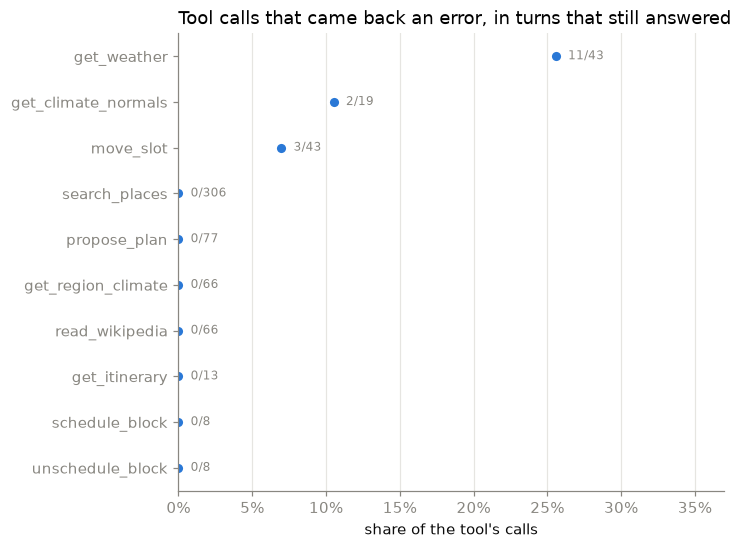

In [11]:
# Figure P3 — recovered tool errors per tool, pooled, every tool called.
order = tools.index.tolist()
fig, ax = plt.subplots(figsize=(6.4, 0.42 * len(order) + 1.2))
figures.rate_plot(ax, {"pooled": tool_rates}, "Tool calls that came back an error, in turns that still answered",
                  "share of the tool's calls", colors={"pooled": figures.SERIES}, order=order)
ax.get_legend() and ax.get_legend().remove()
save(fig, "P3_recovered_errors"); plt.show()

In [12]:
print(f"figures written to {save.dir.resolve()}")

figures written to C:\Users\gian-\Documents\GitHub\trip_tonic\research\regression-testing\notebooks\sim\figures\pooled
